# 04 · Học máy so với các mô hình xử lý ảnh của AEGIS

**Câu hỏi.** Mô hình **học máy** có phát hiện được ảnh do AI tạo không, và có làm tốt bằng hoặc hơn các mô hình
**xử lý ảnh bằng học sâu** mà AEGIS dùng không, kể cả khi ảnh bị nén JPEG, làm mờ hay đến từ generator chưa thấy?

| Nhóm | Mô hình | Ghi chú |
|---|---|---|
| Học sâu (AEGIS gốc) | `clip_expert`, `dinov2_expert` | CLIP ViT-L/14, DINOv2 ViT-B/14 đóng băng + head tuyến tính |
| | `freq_expert` | CNN SRM 1,17 triệu tham số, huấn luyện từ đầu |
| | `static_lr`, `aegis` | kết hợp 3 chuyên gia: trọng số cố định / gating theo từng ảnh |
| **Học máy** | **`rbf_svm`** | SVM kernel Gauss (nhóm kernel) |
| | **`random_forest`** | 300 cây quyết định, bỏ phiếu (nhóm bagging) |
| | **`xgboost`** | cây tăng cường gradient (nhóm boosting) |

**Đầu vào của mô hình học máy**

* `handcrafted`: **92 đặc trưng thủ công** tính thẳng từ điểm ảnh (màu, phổ tần số, nhiễu SRM, texture LBP,
  gradient). **Không dùng mạng nơ-ron nào**: đây là câu trả lời trực tiếp cho câu hỏi trên.
* `clip`, `dinov2`: embedding của CLIP / DINOv2. Cùng đặc trưng với chuyên gia của AEGIS, chỉ khác bộ phân loại.

**Giao thức công bằng.** Học máy huấn luyện trên `train_experts` (cùng ảnh với chuyên gia AEGIS), chọn siêu tham số
theo AUROC trên `val_gating_fit`, hiệu chỉnh xác suất (Platt) trên split đó, rồi đánh giá **một lần** trên
`test_benchmark` và `s4_eval`, **cùng ảnh** với các mô hình AEGIS. S4 không dùng few-shot cho bất kỳ phương pháp
nào. Khoảng tin cậy 95%: bootstrap ghép cặp theo ảnh gốc, so với `aegis`.

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, Image, display

from src.core.config import load_config
from src.core.contracts import SplitManifest

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 40)
cfg = load_config()
print("repo:", ROOT)

repo: c:\Users\Admin\OneDrive - Saigon University\Documents\aegis-ai-forensics


In [2]:
# Bộ dữ liệu thật (GenImage đã chuẩn hoá). Nếu chưa có, notebook tự chuyển sang DEMO MODE:
# ảnh tổng hợp + embedding giả lập, chạy trên CPU trong ~1 phút. Số liệu DEMO không có ý nghĩa khoa học.
MANIFEST = ROOT / "data/normalized_v2/manifest.json"
DEMO = not MANIFEST.exists()
if DEMO:
    from src.models.demo_features import build_demo
    cfg, man = build_demo(ROOT / "data/demo", scale=6, cfg=cfg)
    MANIFEST = ROOT / "data/demo/images/manifest.json"
else:
    man = SplitManifest.load(MANIFEST)
print("DEMO MODE" if DEMO else "REAL DATA", "|", len(man.records), "records |", MANIFEST)

REAL DATA | 32170 records | c:\Users\Admin\OneDrive - Saigon University\Documents\aegis-ai-forensics\data\normalized_v2\manifest.json


In [3]:
from src.data.handcrafted import FEATURE_NAMES, build_cache
from src.evaluation.ml_comparison import (DEEP_METHODS, DEEP_SET, FEATURE_SETS, HEAD_VARIANTS, REFERENCE, load_all,
                                          run_comparison, run_fusion_comparison)
from src.learning.classic_models import DEFAULT_MODELS, describe_models

FEATURES = list(FEATURE_SETS)          # ["handcrafted", "clip", "dinov2"]
HEADS = list(HEAD_VARIANTS)            # ["clean", "aug"]: ảnh train chỉ sạch / thêm ảnh bị nén, làm mờ
MODELS = list(DEFAULT_MODELS)          # ["rbf_svm", "random_forest", "xgboost"]
DEEP = list(DEEP_METHODS)              # các mô hình xử lý ảnh của AEGIS
B = 300 if DEMO else 2000
OUT = ROOT / ("reports/demo_ml_comparison" if DEMO else "reports/ml_comparison")
HV = HEADS[0]                          # biến thể dùng cho các biểu đồ (đổi thành "aug" để xem biến thể kia)
FS = "clip+dinov2"                     # bộ đặc trưng cho mục 8 (học không giám sát)
display(pd.DataFrame([{"mô hình": m, "nhóm": "Học sâu (AEGIS)", "mô tả": d} for m, d in DEEP_METHODS.items()]
                     + [{"mô hình": r["model"], "nhóm": f"Học máy ({r['family']})", "mô tả": r["note"]}
                        for r in describe_models(MODELS)]))

,mô hình,nhóm,mô tả
0,clip_expert,Học sâu (AEGIS),CLIP ViT-L/14 (frozen) + linear head
1,dinov2_expert,Học sâu (AEGIS),DINOv2 ViT-B/14 (frozen) + linear head
2,freq_expert,Học sâu (AEGIS),"SRM high-pass CNN (1.17 M params, trained from..."
3,static_lr,Học sâu (AEGIS),"3 experts, fixed learned weights (logistic reg..."
4,aegis,Học sâu (AEGIS),3 experts + per-image gating network (full AEG...
5,rbf_svm,Học máy (kernel),"SVM, Gaussian (RBF) kernel; standardised input..."
6,random_forest,Học máy (bagging),"random forest, 300 trees, sqrt(d) features per..."
7,xgboost,Học máy (boosting),"XGBoost, 400 boosted trees, lr 0.1 (PCA-128 fo..."


## 1. Đặc trưng thủ công (không dùng học sâu)

| Nhóm | Số chiều | Ý nghĩa |
|---|---|---|
| Màu | 18 | trung bình, độ lệch chuẩn, độ lệch (skewness) của R, G, B, H, S, V |
| Phổ tần số | 27 | phổ FFT theo 24 dải bán kính, độ dốc phổ, tỉ lệ năng lượng tần cao/tần thấp |
| Nhiễu SRM | 33 | phần dư của 3 bộ lọc thông cao SRM: trung bình, độ lệch chuẩn, độ nhọn, histogram 8 ngăn |
| Texture | 10 | histogram LBP đồng nhất (8 điểm lân cận) |
| Gradient | 4 | phương sai Laplacian, độ lớn Sobel, mật độ cạnh |

Lần đầu chạy sẽ tính đặc trưng cho mọi ảnh (vài phút trên CPU), lưu vào `data/cache/features/handcrafted_hc1.pt`.
Các lần sau đọc lại từ cache.

2026-11-24 22:55:23,085 | INFO    | aegis.src.data.handcrafted | handcrafted features: computing 32170 images (0 already cached)
2026-11-24 22:56:20,665 | INFO    | aegis.src.data.handcrafted | handcrafted features: 2000/32170 (58s)
2026-11-24 22:56:43,329 | INFO    | aegis.src.data.handcrafted | handcrafted features: 4000/32170 (80s)
2026-11-24 22:57:04,998 | INFO    | aegis.src.data.handcrafted | handcrafted features: 6000/32170 (102s)
2026-11-24 22:58:13,340 | INFO    | aegis.src.data.handcrafted | handcrafted features: 8000/32170 (170s)
2026-11-24 22:59:03,305 | INFO    | aegis.src.data.handcrafted | handcrafted features: 10000/32170 (220s)
2026-11-24 23:00:11,086 | INFO    | aegis.src.data.handcrafted | handcrafted features: 12000/32170 (288s)
2026-11-24 23:01:17,081 | INFO    | aegis.src.data.handcrafted | handcrafted features: 14000/32170 (354s)
2026-11-24 23:02:18,396 | INFO    | aegis.src.data.handcrafted | handcrafted features: 16000/32170 (415s)
2026-11-24 23:03:04,722 | INF

32170 ảnh · 92 đặc trưng


2026-11-24 23:08:21,765 | INFO    | aegis.src.data.handcrafted | handcrafted features: all 32170 records cached (C:\Users\Admin\OneDrive - Saigon University\Documents\aegis-ai-forensics\data\cache\features\handcrafted_hc1.pt)


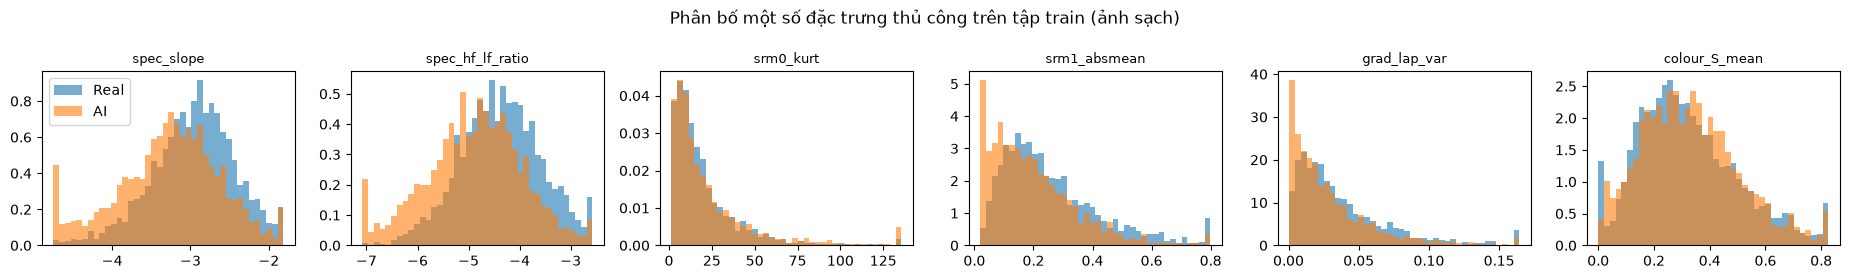

In [4]:
hc = build_cache(cfg, man)
print(len(hc), "ảnh ·", len(FEATURE_NAMES), "đặc trưng")
tr0 = load_all(cfg, man, "handcrafted", "clean")["train"]
show = ["spec_slope", "spec_hf_lf_ratio", "srm0_kurt", "srm1_absmean", "grad_lap_var", "colour_S_mean"]
fig, axes = plt.subplots(1, len(show), figsize=(3.1 * len(show), 2.8))
for ax, name in zip(axes, show):
    j = FEATURE_NAMES.index(name)
    lo, hi = np.percentile(tr0.X[:, j], [1, 99])
    for lab, nm in ((0, "Real"), (1, "AI")):
        ax.hist(np.clip(tr0.X[tr0.y == lab, j], lo, hi), bins=40, alpha=0.6, density=True, label=nm)
    ax.set_title(name, fontsize=9)
axes[0].legend(); plt.suptitle("Phân bố một số đặc trưng thủ công trên tập train (ảnh sạch)")
plt.tight_layout(); plt.show()

## 2. Huấn luyện, chọn siêu tham số, đánh giá

In [5]:
out = run_comparison(cfg, man, FEATURES, HEADS, MODELS, out_dir=OUT, B=B)
res, sig = pd.DataFrame(out["results"]), pd.DataFrame(out["significance"])
tuning, timing = pd.DataFrame(out["tuning"]), pd.DataFrame(out["timing"])
res["method"] = np.where(res.group == "deep", res.model, res.model + " · " + res.feature_set)
res["nhóm"] = np.where(res.group == "deep", "Học sâu (AEGIS)", "Học máy")
print(len(res), "dòng kết quả ->", OUT)

2026-11-24 23:08:24,803 | INFO    | aegis.src.learning.bundle_io | loaded bundle val_gating_fit.pt (n=3360)
2026-11-24 23:08:25,056 | INFO    | aegis.src.learning.bundle_io | loaded bundle test_benchmark.pt (n=11200)
2026-11-24 23:08:25,171 | INFO    | aegis.src.learning.bundle_io | loaded bundle s4_eval.pt (n=6256)
2026-11-24 23:08:25,180 | INFO    | aegis.src.learning.calibration | temperatures fitted: {'clip': 2.3774, 'dinov2': 1.7704, 'freq': 6.4604}
2026-11-24 23:08:34,864 | INFO    | aegis.src.learning.gating | gating fitted: n=3360 loss 0.4706 -> 0.3733
2026-11-24 23:08:34,905 | INFO    | aegis.src.evaluation.ml_comparison | === head_variant=clean feature_set=handcrafted
2026-11-24 23:08:39,768 | INFO    | aegis.src.data.handcrafted | handcrafted features: all 32170 records cached (C:\Users\Admin\OneDrive - Saigon University\Documents\aegis-ai-forensics\data\cache\features\handcrafted_hc1.pt)
2026-11-24 23:08:39,830 | INFO    | aegis.src.evaluation.ml_comparison | train 4800 | v

336 dòng kết quả -> c:\Users\Admin\OneDrive - Saigon University\Documents\aegis-ai-forensics\reports\ml_comparison


### Bảng chính: AUROC theo kịch bản (S2/S3 gộp mọi mức; S4 không thích nghi)

In [6]:
pooled = res[res.level.isin(["clean", "all"])].copy()
pooled["col"] = np.where(pooled.scenario == "S4", "S4 " + pooled.generator, pooled.scenario)
order = ["S1", "S2", "S3"] + sorted(c for c in pooled.col.unique() if c.startswith("S4"))
row_order = DEEP + [f"{m} · {f}" for f in FEATURES for m in MODELS]
main_tab = (pooled.pivot_table(index=["head_variant", "nhóm", "method"], columns="col", values="auroc")[order]
            .reindex(row_order, level="method"))
display(main_tab.style.format("{:.3f}").background_gradient(axis=None, cmap="RdYlGn"))

### Phương pháp tốt nhất ở mỗi kịch bản, và học máy tốt nhất so với AEGIS

In [7]:
rows = []
for (hv, col), g in pooled.groupby(["head_variant", "col"]):
    best = g.loc[g.auroc.idxmax()]
    ml = g[g.group == "ml"]; best_ml = ml.loc[ml.auroc.idxmax()]
    ae = g[g.model == "aegis"].auroc.iloc[0]
    rows.append({"head": hv, "kịch bản": col, "tốt nhất": best.method, "AUROC": best.auroc,
                 "học máy tốt nhất": best_ml.method, "AUROC học máy": best_ml.auroc, "AEGIS": ae,
                 "học máy − AEGIS": best_ml.auroc - ae})
display(pd.DataFrame(rows).set_index(["head", "kịch bản"]).loc[:, :].style.format(
    {"AUROC": "{:.3f}", "AUROC học máy": "{:.3f}", "AEGIS": "{:.3f}", "học máy − AEGIS": "{:+.3f}"}))

## 3. Học máy trên đặc trưng thủ công so với học sâu

Học máy ở đây **không dùng mạng nơ-ron nào**; học sâu là các mô hình của AEGIS.

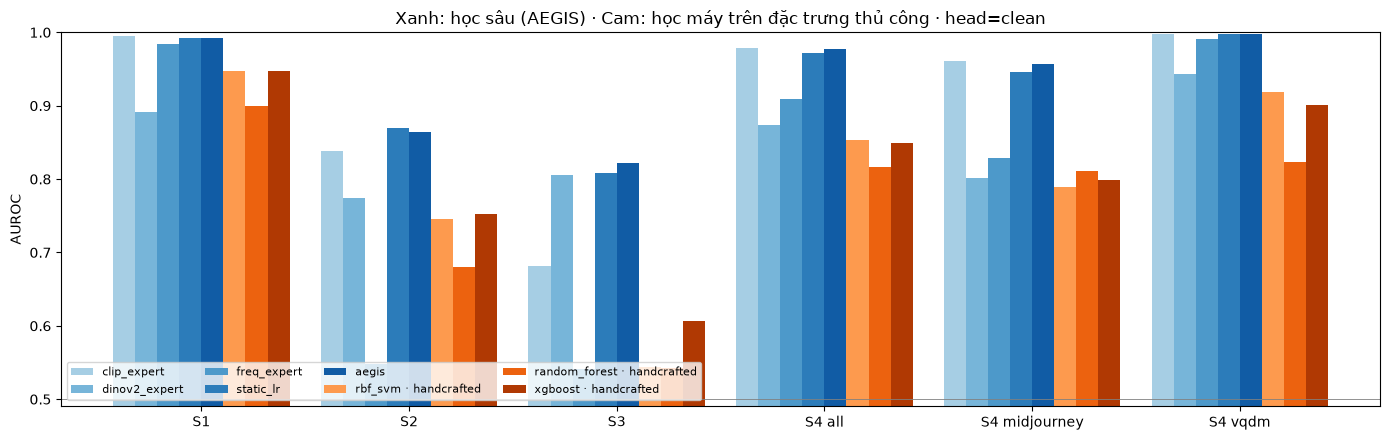

In [8]:
methods = DEEP + [f"{m} · handcrafted" for m in MODELS]
sub = pooled[(pooled.head_variant == HV) & pooled.method.isin(methods)]
piv = sub.pivot_table(index="method", columns="col", values="auroc")[order].loc[methods]
ax = piv.T.plot.bar(figsize=(14, 4.5), width=0.85,
                    color=[plt.cm.Blues(0.35 + 0.12 * i) for i in range(len(DEEP))]
                    + [plt.cm.Oranges(0.45 + 0.2 * i) for i in range(len(MODELS))])
ax.set_ylim(max(0.3, np.nanmin(piv.values) - 0.05), 1.0); ax.set_ylabel("AUROC"); ax.axhline(0.5, color="gray", lw=0.6); ax.set_xlabel("")
ax.set_title(f"Xanh: học sâu (AEGIS) · Cam: học máy trên đặc trưng thủ công · head={HV}")
ax.legend(ncol=4, fontsize=8, loc="lower left"); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 4. Độ bền dưới từng mức suy giảm (S2 JPEG, S3 blur/resize)

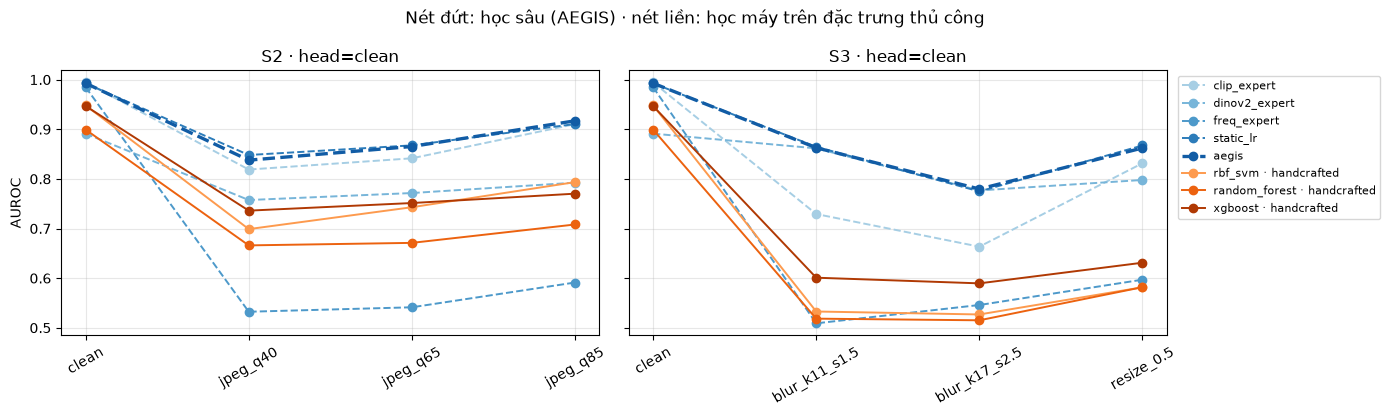

In [9]:
lv = res[(res.head_variant == HV) & res.method.isin(methods) & res.scenario.isin(["S1", "S2", "S3"])
         & (res.level != "all")]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, scen in zip(axes, ["S2", "S3"]):
    d = lv[lv.scenario.isin(["S1", scen])]
    levels = ["clean"] + sorted(d[d.scenario == scen].level.unique())
    for i, m in enumerate(methods):
        y = d[d.method == m].set_index("level").auroc.reindex(levels)
        deep = m in DEEP
        ax.plot(levels, y.values, marker="o", ls="--" if deep else "-", lw=2.4 if m == "aegis" else 1.4,
                color=plt.cm.Blues(0.35 + 0.12 * i) if deep else plt.cm.Oranges(0.45 + 0.2 * (i - len(DEEP))),
                label=m)
    ax.set_title(f"{scen} · head={HV}"); ax.tick_params(axis="x", rotation=30); ax.grid(alpha=0.3)
axes[0].set_ylabel("AUROC"); axes[1].legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.suptitle("Nét đứt: học sâu (AEGIS) · nét liền: học máy trên đặc trưng thủ công")
plt.tight_layout(); plt.show()

## 5. Kiểm định ý nghĩa thống kê: ΔAUROC = học máy − AEGIS

Thanh ngang là khoảng tin cậy 95% (bootstrap theo ảnh gốc). Xanh: học máy tốt hơn AEGIS có ý nghĩa; đỏ: kém hơn có
ý nghĩa; xám: không khác biệt có ý nghĩa.

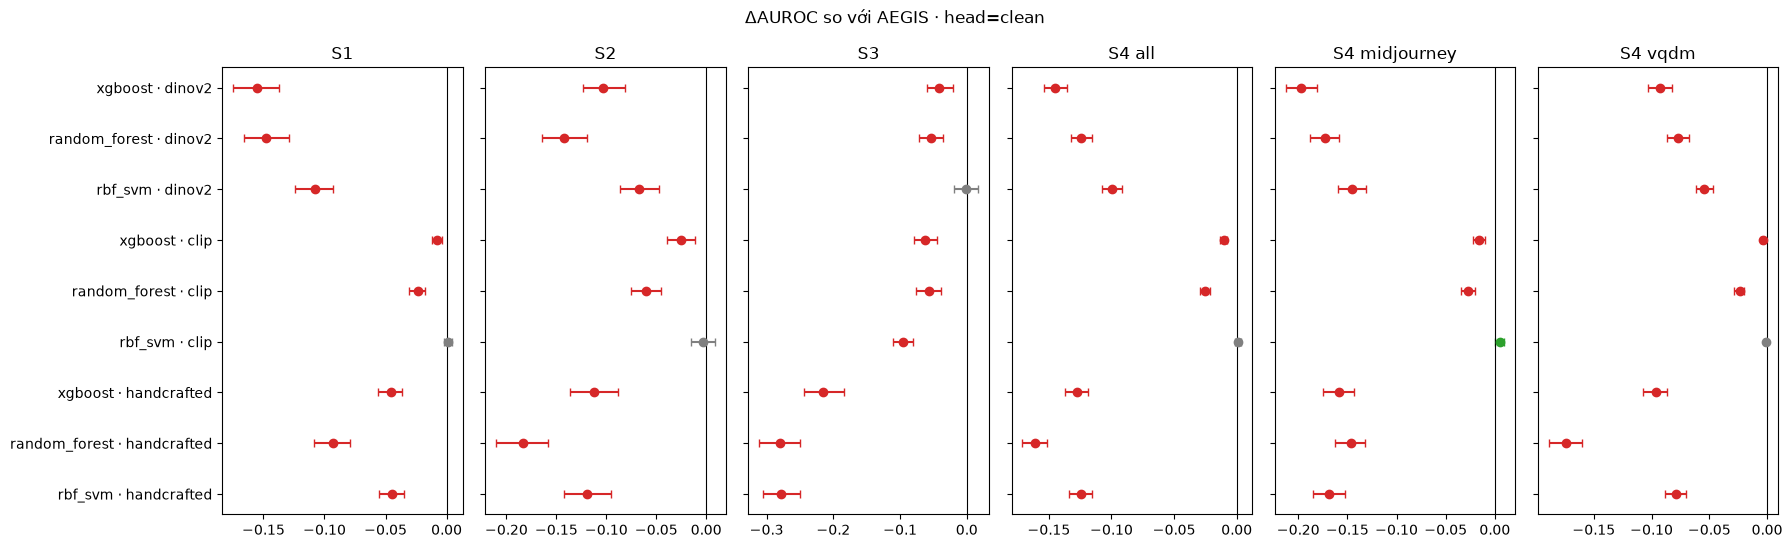

col,S1,S2,S3,S4 all,S4 midjourney,S4 vqdm
method,,,,,,
rbf_svm · handcrafted,-0.045,-0.119,-0.278,-0.124,-0.168,-0.079
random_forest · handcrafted,-0.093,-0.184,-0.279,-0.161,-0.147,-0.174
xgboost · handcrafted,-0.046,-0.112,-0.215,-0.128,-0.159,-0.096
rbf_svm · clip,+0.001,-0.003,-0.096,+0.001,+0.005,-0.001
random_forest · clip,-0.024,-0.060,-0.057,-0.026,-0.027,-0.024
xgboost · clip,-0.008,-0.025,-0.062,-0.010,-0.016,-0.004
rbf_svm · dinov2,-0.108,-0.068,-0.001,-0.099,-0.146,-0.054
random_forest · dinov2,-0.148,-0.142,-0.054,-0.124,-0.173,-0.077
xgboost · dinov2,-0.156,-0.103,-0.041,-0.145,-0.197,-0.092


In [10]:
s = sig[(sig.metric == "auroc") & sig.level.isin(["clean", "all"]) & (sig.head_variant == HV)].copy()
s["col"] = np.where(s.scenario == "S4", "S4 " + s.generator, s.scenario)
s["method"] = s.model + " · " + s.feature_set
labels = [f"{m} · {f}" for f in FEATURES for m in MODELS]
cols = [c for c in order if c in set(s.col)]
fig, axes = plt.subplots(1, len(cols), figsize=(3.0 * len(cols), 0.45 * len(labels) + 1.5), sharey=True)
for ax, c in zip(np.atleast_1d(axes), cols):
    d = s[s.col == c].set_index("method").reindex(labels)
    for y_, (_, r) in zip(range(len(d)), d.iterrows()):
        if pd.isna(r.delta):
            continue
        col = "gray" if not r.significant else ("tab:green" if r.delta > 0 else "tab:red")
        ax.errorbar(r.delta, y_, xerr=[[r.delta - r.ci_lo], [r.ci_hi - r.delta]], fmt="o", color=col, capsize=3)
    ax.axvline(0, color="black", lw=0.8); ax.set_title(c); ax.set_yticks(range(len(labels)), labels)
fig.suptitle(f"ΔAUROC so với AEGIS · head={HV}"); plt.tight_layout(); plt.show()
display(s.pivot_table(index="method", columns="col", values="delta").reindex(labels)[cols]
        .style.format("{:+.3f}").background_gradient(axis=None, cmap="RdYlGn", vmin=-0.2, vmax=0.2))

## 6. Cùng đặc trưng, khác bộ phân loại

Trên cùng embedding CLIP (hoặc DINOv2), chuyên gia của AEGIS dùng head tuyến tính, còn ở đây thay bằng SVM, Random
Forest, XGBoost. So sánh này cho biết học máy phi tuyến có làm chuyên gia mạnh hơn không.

In [11]:
pairs = [("clip_expert", "clip"), ("dinov2_expert", "dinov2")]
same = []
for expert, f in pairs:
    if f not in FEATURES:
        continue
    same += [expert] + [f"{m} · {f}" for m in MODELS]
display(pooled[pooled.method.isin(same)].pivot_table(index=["head_variant", "method"], columns="col", values="auroc")
        [order].reindex(same, level="method").style.format("{:.3f}").background_gradient(axis=None, cmap="RdYlGn"))

### Chi phí của các mô hình học máy

Thời gian fit (giây, cho siêu tham số được chọn) và thời gian dự đoán (ms cho 1.000 ảnh), trên CPU. Để so sánh: các
mô hình học sâu cần GPU để trích embedding (CLIP khoảng 25 phút cho cả bộ dữ liệu trên RTX 4060), còn đặc trưng thủ
công chỉ cần CPU.

In [12]:
t = timing.copy()
t["method"] = t.model + " · " + t.feature_set
display(t.pivot_table(index="method", columns="head_variant", values=["fit_seconds", "predict_ms_per_1k"])
        .reindex([f"{m} · {f}" for f in FEATURES for m in MODELS]).style.format("{:.1f}"))

## 7. Tầng fusion: học máy thay cho mạng gating

Đầu vào: chất lượng ảnh (3) | entropy (3) | khoảng cách OOD (3) | xác suất đã hiệu chỉnh của 3 chuyên gia (3).
Fit trên `val_gating_fit`, chọn siêu tham số trên `val_gating_verify`, đánh giá trên test. Đối chứng là
`static_lr` (trọng số cố định) và `aegis` (gating theo từng ảnh). S4 ở đây là *chưa thích nghi few-shot*.

In [13]:
fus = pd.DataFrame(sum((run_fusion_comparison(cfg, hv, MODELS) for hv in HEADS), []))
fus_p = fus[fus.level.isin(["clean", "all"])]
display(fus_p.pivot_table(index=["head_variant", "method"], columns="scenario", values="auroc")
        .style.format("{:.3f}").background_gradient(axis=None, cmap="RdYlGn"))
fus.to_csv(OUT / "fusion_level.csv", index=False)

2026-11-24 23:15:12,384 | INFO    | aegis.src.learning.bundle_io | loaded bundle val_gating_fit.pt (n=3360)
2026-11-24 23:15:12,472 | INFO    | aegis.src.learning.bundle_io | loaded bundle test_benchmark.pt (n=11200)
2026-11-24 23:15:12,503 | INFO    | aegis.src.learning.bundle_io | loaded bundle val_gating_verify.pt (n=1440)
2026-11-24 23:15:12,545 | INFO    | aegis.src.learning.bundle_io | loaded bundle s4_eval.pt (n=6256)
2026-11-24 23:15:12,551 | INFO    | aegis.src.learning.calibration | temperatures fitted: {'clip': 2.3774, 'dinov2': 1.7704, 'freq': 6.4604}
2026-11-24 23:15:13,953 | INFO    | aegis.src.learning.gating | gating fitted: n=3360 loss 0.4706 -> 0.3733
2026-11-24 23:15:18,973 | INFO    | aegis.src.learning.bundle_io | loaded bundle val_gating_fit.pt (n=3360)
2026-11-24 23:15:19,075 | INFO    | aegis.src.learning.bundle_io | loaded bundle test_benchmark.pt (n=11200)
2026-11-24 23:15:19,102 | INFO    | aegis.src.learning.bundle_io | loaded bundle val_gating_verify.pt (n=

## 8. Học không giám sát trên embedding

* **PCA / t-SNE**: embedding có tự tách Real và AI, hay tách theo generator không?
* **K-means**: cụm có trùng với generator không (Adjusted Rand Index, purity)?
* **Phát hiện ảnh lạ**: chỉ học trên ảnh sạch của generator đã thấy, có nhận ra ảnh S4 (Midjourney, VQDM) là lạ không?
  So sánh Isolation Forest, One-Class SVM với khoảng cách cosine tới tâm (cách AEGIS đang dùng).

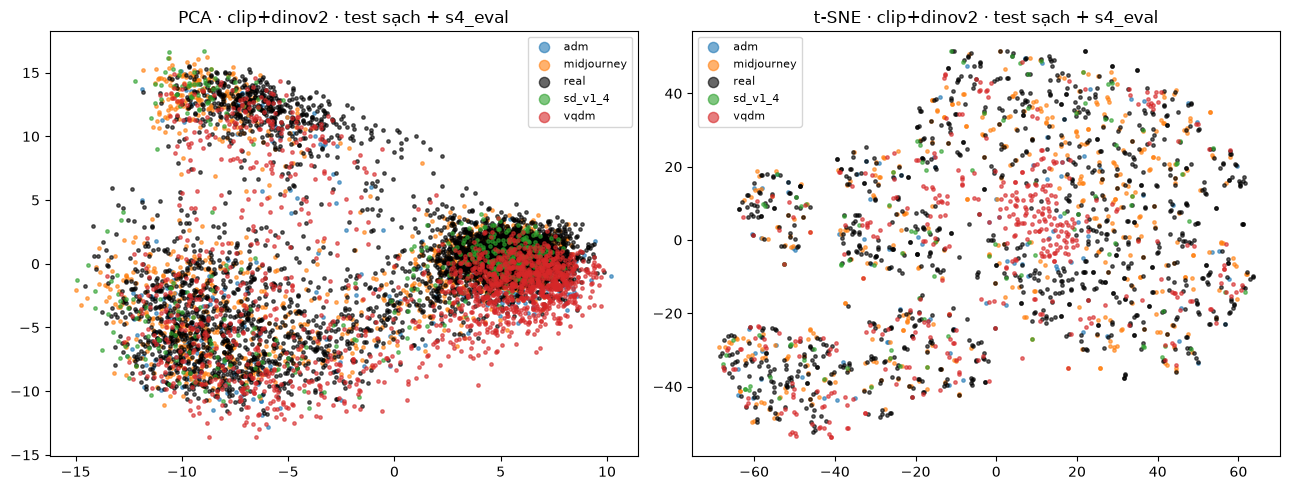

In [14]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
data = load_all(cfg, man, FS, "clean")
te = data["test"]
m_clean = np.array([s is None for s in te.scenario])
Xv = np.concatenate([te.X[m_clean], data["s4"].X])
gv = np.array([g for g, c in zip(te.generator, m_clean) if c] + list(data["s4"].generator))
Z = StandardScaler().fit_transform(Xv)
P2 = PCA(2, random_state=0).fit_transform(Z)
idx = np.random.default_rng(0).choice(len(Z), min(2000, len(Z)), replace=False)
T2 = TSNE(2, random_state=0, init="pca", perplexity=min(30, len(idx) // 4)).fit_transform(Z[idx])
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, E, gg, title in ((axes[0], P2, gv, "PCA"), (axes[1], T2, gv[idx], "t-SNE")):
    for g in sorted(set(gg)):
        k = gg == g
        ax.scatter(E[k, 0], E[k, 1], s=6, alpha=0.6, label=g, c="black" if g == "real" else None)
    ax.set_title(f"{title} · {FS} · test sạch + s4_eval"); ax.legend(markerscale=3, fontsize=8)
plt.tight_layout(); plt.show()

In [15]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
Zp = PCA(min(50, Z.shape[1]), random_state=0).fit_transform(Z)
rows = []
for k in (2, len(set(gv))):
    lab = KMeans(k, n_init=10, random_state=0).fit_predict(Zp)
    target = gv if k > 2 else (gv != "real").astype(int)
    purity = pd.crosstab(lab, target).max(axis=1).sum() / len(lab)
    rows.append({"k": k, "so với": "generator" if k > 2 else "Real/AI", "ARI": adjusted_rand_score(target, lab),
                 "NMI": normalized_mutual_info_score(target, lab), "purity": purity})
display(pd.DataFrame(rows))

,k,so với,ARI,NMI,purity
0,2,Real/AI,-1.345e-04,5.277e-06,0.509
1,5,generator,1.939e-01,2.033e-01,0.612


In [16]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score
from sklearn.svm import OneClassSVM
tr = data["train"]
sc = StandardScaler().fit(tr.X)
pca = PCA(min(64, tr.X.shape[1]), random_state=0).fit(sc.transform(tr.X))
f = lambda X: pca.transform(sc.transform(X))
s4_ai = data["s4"].X[data["s4"].y == 1]
seen = te.X[m_clean]
X_ood = np.concatenate([seen, s4_ai]); y_ood = np.r_[np.zeros(len(seen)), np.ones(len(s4_ai))]
centroid = tr.X.mean(0)
cosd = 1 - (X_ood @ centroid) / (np.linalg.norm(X_ood, axis=1) * np.linalg.norm(centroid) + 1e-9)
scores = {
    "cosine distance (AEGIS)": cosd,
    "Isolation Forest": -IsolationForest(n_estimators=300, random_state=0).fit(f(tr.X)).score_samples(f(X_ood)),
    "One-Class SVM": -OneClassSVM(nu=0.1, gamma="scale").fit(f(tr.X)).score_samples(f(X_ood)),
}
display(pd.DataFrame({"AUROC phát hiện ảnh S4 là lạ": {k: roc_auc_score(y_ood, v) for k, v in scores.items()}}))

,AUROC phát hiện ảnh S4 là lạ
cosine distance (AEGIS),0.486
Isolation Forest,0.521
One-Class SVM,0.545


## 9. Gợi ý viết phần thảo luận trong báo cáo

* **Câu hỏi chính:** học máy trên đặc trưng thủ công (không học sâu) đạt bao nhiêu so với AEGIS ở ảnh sạch (S1)?
  Khoảng cách đó có ý nghĩa thống kê không (mục 5)?
* **Độ bền:** dưới JPEG/blur (S2/S3), đặc trưng thủ công (phổ tần số, nhiễu SRM) có sụp giống chuyên gia tần số của
  AEGIS không? Mô hình học máy nào bền nhất?
* **Generator chưa thấy (S4):** học máy trên đặc trưng thủ công tổng quát hoá tới Midjourney / VQDM thế nào so với CLIP?
* **Cùng đặc trưng, khác bộ phân loại (mục 6):** SVM / RF / XGBoost trên embedding có hơn head tuyến tính của AEGIS
  không? Nếu không, điểm mạnh của AEGIS nằm ở đặc trưng học sâu chứ không ở bộ phân loại.
* **Học máy thay gating (mục 7):** stacking bằng SVM / RF / XGBoost có bằng gating của AEGIS không?
* **Chi phí:** học máy trên đặc trưng thủ công chạy hoàn toàn trên CPU; học sâu cần GPU. Đánh đổi có đáng không?
* Luôn so với mức sàn `quality_only` (≈0.63 trên dữ liệu thật): đặc trưng thủ công dễ học shortcut định dạng file hơn.